# What machine learning is; overfitting, underfitting and the bias-variance tradeoff — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D001_ML_overfitting_underfitting.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

# Overfitting and underfitting: a depth curve

The same model family, fitted at every complexity from too simple to too flexible, scored on data it trained on and on data it did not.

## Setup

In [92]:
## Core libraries
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from scipy import stats


# ML Preprocessing libraries
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
StandardScaler,
MinMaxScaler,RobustScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder,PolynomialFeatures
)

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# feature selection libraries
from sklearn.feature_selection import (SelectKBest,
VarianceThreshold,
SelectFromModel,
RFE,f_classif)

# Models and evaluation
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor,plot_tree
from sklearn.model_selection import train_test_split,cross_val_score,GridSearchCV
from sklearn.metrics import (classification_report, 
confusion_matrix,
ConfusionMatrixDisplay,
f1_score,accuracy_score,precision_score,recall_score)
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score,PredictionErrorDisplay,ConfusionMatrixDisplay

# pipeline 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# imbalanced learning 
from imblearn.over_sampling import SMOTE

![](https://media.licdn.com/dms/image/v2/D4D12AQH0NVHuB7sAJQ/article-cover_image-shrink_600_2000/article-cover_image-shrink_600_2000/0/1726318143139?e=2147483647&v=beta&t=S-qSTdS2BFFRMQB5MuVyCCpP68i8zFt-3vAEVs5tDEo)

In [ ]:
# ═══ CHECKPOINT — "Load and prepare auto_mpg" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, LabelEncoder, OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import SelectKBest, VarianceThreshold, SelectFromModel, RFE, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score, precision_score, recall_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, PredictionErrorDisplay, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE

print("Checkpoint restored. Ready for: Load and prepare auto_mpg")

## Load and prepare auto_mpg

In [ ]:
# TODO: compute `df`
# Name your result: df

In [3]:
df

,mpg,displ,hp,weight,accel,origin,size
0,18.0,250.0,88,3139,14.5,US,15.0
1,9.0,304.0,193,4732,18.5,US,20.0
2,36.1,91.0,60,1800,16.4,Asia,10.0
3,18.5,250.0,98,3525,19.0,US,15.0
4,34.3,97.0,78,2188,15.8,Europe,10.0
...,...,...,...,...,...,...,...
387,18.0,250.0,88,3021,16.5,US,15.0
388,27.0,151.0,90,2950,17.3,US,10.0
389,29.5,98.0,68,2135,16.6,Asia,10.0
390,17.5,250.0,110,3520,16.4,US,15.0


In [ ]:
# TODO: compute `df` from `origin`
# Name your result: df

In [ ]:
# TODO: write the code for this step
# Name your result: X, y

In [ ]:
# ═══ CHECKPOINT — "Train/test split and scaling" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, LabelEncoder, OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import SelectKBest, VarianceThreshold, SelectFromModel, RFE, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score, precision_score, recall_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, PredictionErrorDisplay, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE
df = pd.read_csv('../../00-data/auto_mpg.csv')
df = pd.get_dummies(df, columns=['origin'], sparse=False, drop_first=True, dtype=float)
X = df.iloc[:, 1:]
y = df['mpg']

print("Checkpoint restored. Ready for: Train/test split and scaling")

## Train/test split and scaling

In [ ]:
# TODO: call `train_test_split`

In [ ]:
# TODO: compute `scaler`, `X_train_s`, `X_test_s`
# Name your result: scaler, X_train_s, X_test_s

## Depth curves: from underfitting to overfitting

In [ ]:
# TODO: draw a `plt.figure`
# Name your result: depths, train_scores, test_scores, dlt_depth

In [20]:
df.shape

(392, 8)

In [ ]:
# ═══ CHECKPOINT — "Synthetic data: the same curve on made-up data" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, LabelEncoder, OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import SelectKBest, VarianceThreshold, SelectFromModel, RFE, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score, precision_score, recall_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, PredictionErrorDisplay, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE
df = pd.read_csv('../../00-data/auto_mpg.csv')
df = pd.get_dummies(df, columns=['origin'], sparse=False, drop_first=True, dtype=float)
X = df.iloc[:, 1:]
y = df['mpg']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=12)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
depths = range(1, 21)
train_scores = []
test_scores = []
for d in depths:
    dlt_depth = DecisionTreeRegressor(max_depth=d, random_state=12)
    dlt_depth.fit(X_train_s, y_train)
    train_scores.append(dlt_depth.score(X_train_s, y_train))
    test_scores.append(dlt_depth.score(X_test_s, y_test))

print("Checkpoint restored. Ready for: Synthetic data: the same curve on made-up data")

## Synthetic data: the same curve on made-up data

In [73]:
from sklearn.datasets import make_regression, make_classification

In [ ]:
# TODO: call `make_regression`

In [75]:
# - train test splot
# - decision regressor
# - RMSE R2score
# - plot training and testing r2

In [ ]:
# TODO: call `train_test_split`

In [ ]:
# TODO: compute `scaler`, `X_train_s`, `X_test_s`
# Name your result: scaler, X_train_s, X_test_s

In [ ]:
# TODO: compute `dlt`
# Name your result: dlt

In [ ]:
# TODO: compute `y_pred`
# Name your result: y_pred

In [80]:
r2_score(y_test,y_pred)

0.8322960766627407

In [ ]:
# TODO: call `np.sqrt`

In [ ]:
# TODO: draw a `plt.subplots`

In [ ]:
# TODO: draw a `plt.figure`
# Name your result: depths, train_scores, test_scores, dlt_depth

In [107]:
X,y = make_classification(n_samples=1000000,n_features=23,n_informative=15,n_redundant=8,random_state=12)

In [108]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=12)

In [109]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [110]:
clf = DecisionTreeClassifier(random_state=12)
clf.fit(X_train_s,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,12
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,12
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [111]:
y_pred = clf.predict(X_test_s)

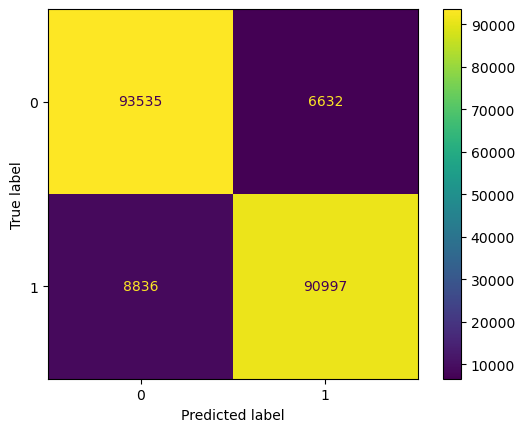

In [112]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)

In [113]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.91      0.93      0.92    100167
           1       0.93      0.91      0.92     99833

    accuracy                           0.92    200000
   macro avg       0.92      0.92      0.92    200000
weighted avg       0.92      0.92      0.92    200000



In [ ]:
# TODO: draw a `plt.figure`
# Name your result: depths, train_scores, test_scores, dlt_depth